In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Load the dataset using the double-up path
df = pd.read_csv(r"C:\Users\reven\Downloads\Fraud-Detection-AML-DL\data\creditcard.csv\creditcard.csv")
print(f"Dataset Loaded Successfully! Shape: {df.shape}")
print("\nClass Distribution:")
print(df['Class'].value_counts(normalize=True)) # Shows percentages

Dataset Loaded Successfully! Shape: (284807, 31)

Class Distribution:
Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64


In [14]:
# 1. Prepare Features and Target
X = df.drop('Class', axis=1)
y = df['Class']

# 2. Split (Using stratify to ensure fraud is in both sets)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Train Baseline Random Forest
baseline_model = RandomForestClassifier(n_estimators=10, random_state=42)
baseline_model.fit(X_train, y_train)
print("Phase 1: Baseline Training Complete.")

Phase 1: Baseline Training Complete.


--- BASELINE EVALUATION ---
Accuracy: 0.9996

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.94      0.80      0.86        98

    accuracy                           1.00     56962
   macro avg       0.97      0.90      0.93     56962
weighted avg       1.00      1.00      1.00     56962



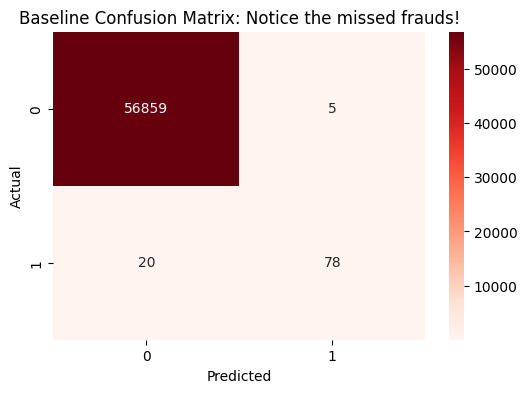

['../../models/rf_baseline_model.joblib']

In [16]:
y_pred = baseline_model.predict(X_test)

print("--- BASELINE EVALUATION ---")
print(f"Accuracy: {baseline_model.score(X_test, y_test):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Plotting the Confusion Matrix
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Reds')
plt.title('Baseline Confusion Matrix: Notice the missed frauds!')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

import joblib; joblib.dump(baseline_model, '../../models/rf_baseline_model.joblib')